# Customer 360: dự đoán mua lại trong 90 ngày

Phần mở rộng ML của dự án SQL Tech360 Retail. Dữ liệu giả lập; mục tiêu học cách thiết kế nhãn, chia dữ liệu theo thời gian và kiểm tra model so với quy tắc đơn giản. Đọc README trước khi chạy. Mọi code mô hình nằm trong customer360_ml.py, không có dịch vụ ngoài hay kết nối SQL bắt buộc.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from customer360_ml import (FEATURES, FEATURE_DESCRIPTIONS, load_data,
                            build_snapshot, model_candidates, run_experiment)
ROOT = Path.cwd()
assert (ROOT / "data" / "fact_order.csv").exists(), "Mở notebook tại thư mục dự án"
customers, orders = load_data(ROOT / "data")
display(pd.DataFrame({"table": ["dim_customer", "fact_order", "Completed"],
                      "rows": [len(customers), len(orders), orders.order_status.eq("Completed").sum()]}))

,table,rows
0,dim_customer,600
1,fact_order,3200
2,Completed,2998


## 1. Xác định nhãn và thông tin được phép dùng

Một dòng là một khách đã từng mua tại ngày T. Nhãn = 1 nếu có Completed sau T đến T+90 ngày; =0 khi đã quan sát đủ 90 ngày nhưng không mua. Dữ liệu đầu vào chỉ lấy 90 ngày trước và tại T. Không dự đoán cho người chưa từng mua.

Ví dụ T=31/03/2025: đầu vào 01/01–31/03; kết quả 01/04–29/06. Không lấy nhóm At Risk chốt 31/12 làm nhãn. Bài giả định Completed đã biết tại order_date vì nguồn thiếu completed_at.

In [2]:
march = build_snapshot(customers, orders, "2025-03-31")
display(march.head())
display(pd.DataFrame({"feature": FEATURES,
                      "meaning": [FEATURE_DESCRIPTIONS[f] for f in FEATURES]}))

,customer_id,recency_capped_91,orders_90d,log_revenue_90d,orders_30d,log_revenue_30d,log_aov_90d,log_max_order_90d,channels_90d,active_30d_blocks,cutoff,label_end,repurchase_90d
0,C0001,24,5,18.815754,1,16.562461,17.206316,17.798298,2,3,2025-03-31,2025-06-29,1
1,C0002,7,2,17.823621,2,17.823621,17.130474,17.621369,1,1,2025-03-31,2025-06-29,1
2,C0003,6,3,18.303810,1,17.956739,17.205198,17.956739,1,3,2025-03-31,2025-06-29,1
3,C0004,38,4,18.357031,0,0.000000,16.970737,17.700122,2,2,2025-03-31,2025-06-29,1
4,C0005,34,4,18.297428,0,0.000000,16.911134,17.300467,4,2,2025-03-31,2025-06-29,1


,feature,meaning
0,recency_capped_91,"Số ngày từ lần mua Completed cuối, chặn tại 91..."
1,orders_90d,Số đơn Completed trong 90 ngày tính cả ngày chốt.
2,orders_30d,Số đơn Completed trong 30 ngày tính cả ngày chốt.
3,log_revenue_90d,log1p(tổng giá trị đơn VND trong 90 ngày).
4,log_revenue_30d,log1p(tổng giá trị đơn VND trong 30 ngày).
5,log_aov_90d,log1p(giá trị đơn trung bình 90 ngày); 0 nếu k...
6,log_max_order_90d,log1p(giá trị đơn cao nhất 90 ngày); 0 nếu khô...
7,channels_90d,Số kênh có đơn Completed trong 90 ngày.
8,active_30d_blocks,"Số khoảng 30 ngày có mua trong 90 ngày, từ 0 đ..."


## 2. Train, Validation và Test theo thời gian

Train chốt 31/03, Validation chốt 30/06, Test chốt 30/09. Các nhãn của bước trước hoàn tất trước ngày dự đoán bước sau. Cùng khách có thể lặp qua mốc vì ta dự đoán tương lai của khách đã biết. ID không vào model.

Hai ứng viên cố định: Logistic Regression và Random Forest nhỏ. Chọn model theo AP Validation, rồi refit Train + Validation để đánh giá Test. Không điều chỉnh code theo kết quả Test.

In [3]:
model_candidates()

{'logistic_regression': Pipeline(steps=[('standardscaler', StandardScaler()),
                 ('logisticregression',
                  LogisticRegression(max_iter=2000, random_state=42))]),
 'random_forest': RandomForestClassifier(max_depth=4, min_samples_leaf=15, n_estimators=300,
                        n_jobs=1, random_state=42)}

In [4]:
experiment = run_experiment(ROOT / "data", ROOT / "results")
display(experiment["splits"])
display(experiment["validation"].round(4))
print("ML được chọn bằng Validation:", experiment["manifest"]["selected_ml"])
print("Quy tắc được chọn bằng Validation:", experiment["manifest"]["selected_rule"])

,split,cutoff,observation_start,label_start,label_end,n,positives,prevalence
0,train,2025-03-31,2025-01-01,2025-04-01,2025-06-29,283,201,0.710247
1,validation,2025-06-30,2025-04-02,2025-07-01,2025-09-28,397,267,0.672544
2,test,2025-09-30,2025-07-03,2025-10-01,2025-12-29,489,315,0.644172


,model,n,positives,prevalence,average_precision,roc_auc,top20_n,precision_at_20pct,recall_at_20pct,lift_at_20pct,brier,accuracy_at_05,precision_at_05,recall_at_05,tn,fp,fn,tp
0,logistic_regression,397,267,0.6725,0.8061,0.6537,80,0.8500,0.2547,1.2639,0.2563,0.6675,0.7228,0.8202,46.0,84.0,48.0,219.0
1,random_forest,397,267,0.6725,0.7922,0.6312,80,0.8500,0.2547,1.2639,0.2105,0.6499,0.7162,0.7940,46.0,84.0,55.0,212.0
2,recency_rule,397,267,0.6725,0.7436,0.5986,80,0.7750,0.2322,1.1523,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,frequency_rule,397,267,0.6725,0.7936,0.6680,80,0.8750,0.2622,1.3010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,constant_prior,397,267,0.6725,0.6725,0.5000,80,0.6725,0.2015,1.0000,0.2217,0.6725,0.6725,1.0000,0.0,130.0,0.0,267.0


ML được chọn bằng Validation: logistic_regression
Quy tắc được chọn bằng Validation: frequency_rule


## 3. Đánh giá trên Test

AP và ROC-AUC đo xếp hạng. Precision@20% cho biết tỷ lệ mua lại ở nhóm 20% điểm cao nhất. Lift chia tỷ lệ này cho tỷ lệ mua lại chung. Brier đo sai số xác suất; thấp hơn tốt hơn. Ngưỡng 0,5 chỉ để minh họa, chưa có chi phí để tối ưu ngưỡng. Quy tắc xếp hạng không có Brier hoặc ngưỡng xác suất nên các ô đó để trống.

,model,n,positives,prevalence,average_precision,roc_auc,top20_n,precision_at_20pct,recall_at_20pct,lift_at_20pct,brier,accuracy_at_05,precision_at_05,recall_at_05,tn,fp,fn,tp
0,logistic_regression,489,315,0.6442,0.7287,0.5787,98,0.7449,0.2317,1.1564,0.2288,0.6094,0.6732,0.7651,57.0,117.0,74.0,241.0
1,recency_rule,489,315,0.6442,0.7293,0.6064,98,0.7857,0.2444,1.2197,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,frequency_rule,489,315,0.6442,0.7122,0.5833,98,0.7653,0.2381,1.1880,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,constant_prior,489,315,0.6442,0.6442,0.5000,98,0.6442,0.2004,1.0000,0.2312,0.6442,0.6442,1.0000,0.0,174.0,0.0,315.0


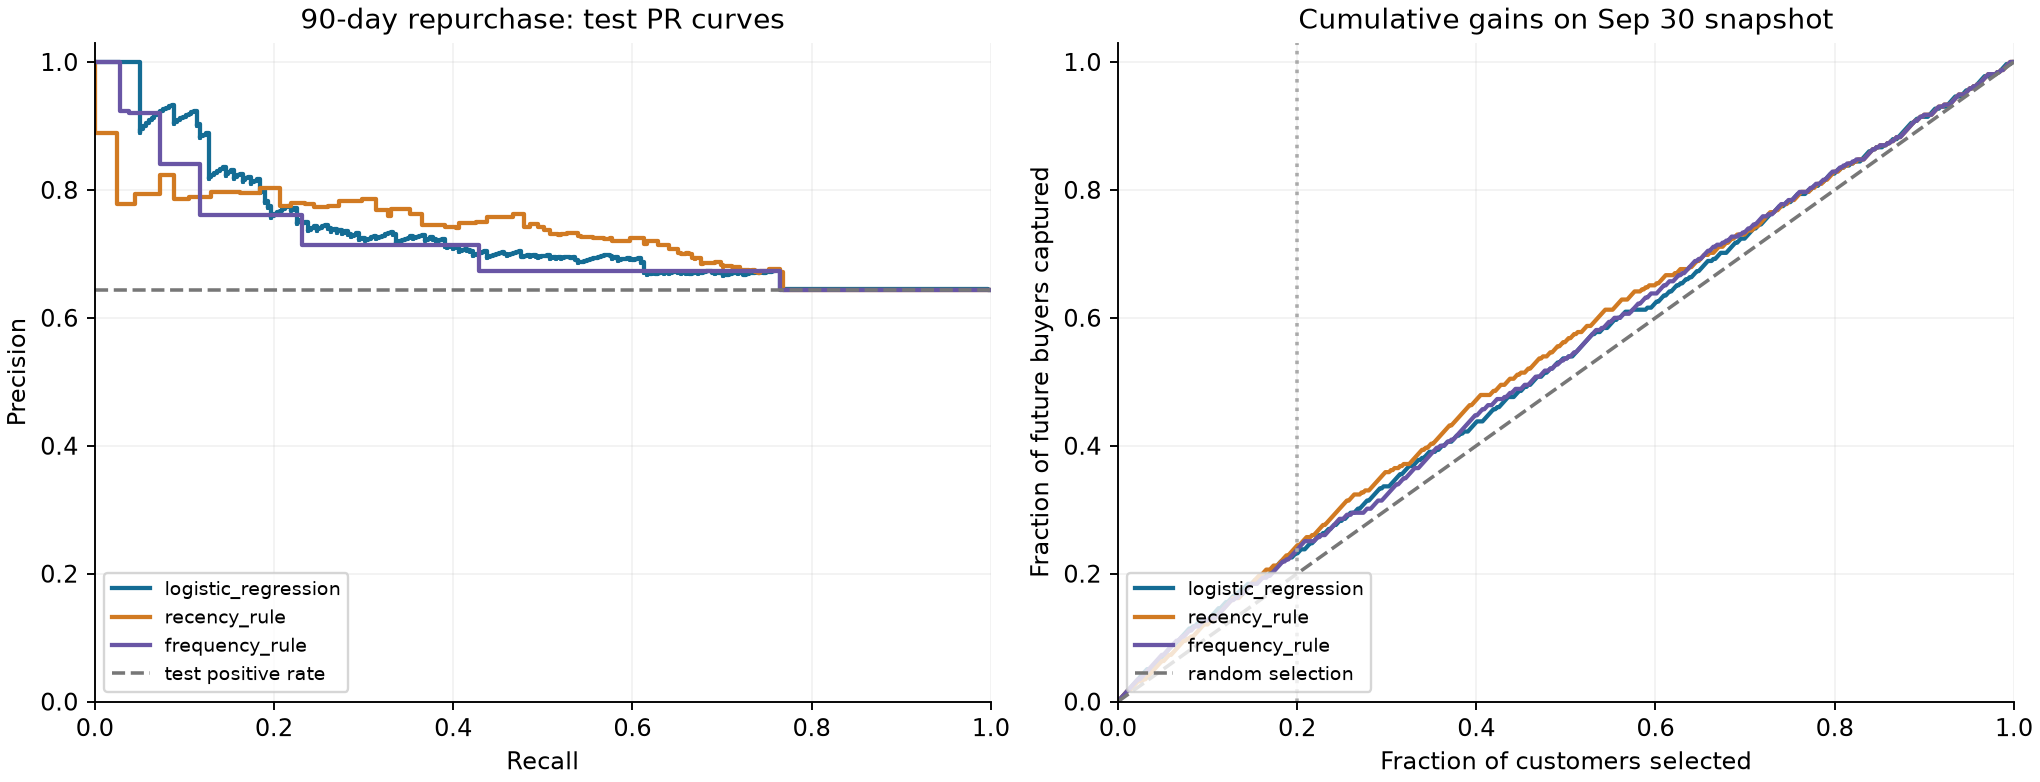

,comparison,statistic,estimate,ci95_low,ci95_high,resamples
0,selected_ml_minus_validation_selected_rule,average_precision_difference,0.0164,0.0047,0.0277,1000


In [5]:
display(experiment["test"].round(4))
display(Image(filename=str(ROOT / "results" / "evaluation.png")))
display(pd.read_csv(ROOT / "results" / "bootstrap_ap_difference.csv").round(4))

## 4. Diễn giải kết quả

logistic_regression có AP Test 0.729, cao hơn frequency_rule (0.712). Khoảng bootstrap không chứa 0, nhưng chỉ phản ánh mẫu khách tại một mốc Test; cần thêm mốc kiểm tra độc lập.

Quy tắc mua gần đây có AP 0.7293 và Precision@20% 78.6%; ML có AP 0.7287 và Precision@20% 74.5%. ML chưa cho thấy lợi thế rõ ràng trước các quy tắc đơn giản. Accuracy ML 60.9% tại ngưỡng 0,5 còn thấp hơn cách luôn đoán mua lại (64.4%); không dùng riêng accuracy để tuyên bố thành công.

Khoảng bootstrap lấy mẫu lại khách tại một mốc Test, không đo được mùa vụ hoặc độ bất định của quá trình train. Chọn ML tốt nhất trong các ứng viên chưa chứng minh ML tốt hơn quy tắc.

Permutation importance dưới đây chỉ là chẩn đoán sau Test, không được dùng để sửa model rồi tiếp tục báo cùng Test. Các biến liên quan với nhau có thể chia sẻ tầm quan trọng, không diễn giải nhân quả.

In [6]:
display(pd.read_csv(ROOT / "results" / "permutation_importance.csv").round(4))

,feature,ap_decrease_mean,ap_decrease_std
0,orders_90d,0.0876,0.0129
1,orders_30d,0.0222,0.0081
2,log_revenue_90d,0.0030,0.0041
3,log_aov_90d,-0.0025,0.0012
4,log_max_order_90d,-0.0025,0.0017
5,channels_90d,-0.0027,0.0029
6,log_revenue_30d,-0.0033,0.0012
7,active_30d_blocks,-0.0049,0.0022
8,recency_capped_91,-0.0129,0.0052


## 5. Chấm điểm minh họa tại cuối năm

Pipeline còn fit một bản riêng trên cả ba mốc đã có nhãn để chấm điểm ngày 31/12/2025 cho 90 ngày tới, đến 31/03/2026. Đây là chấm điểm hồi cứu. Không có dữ liệu 2026 nên không thể đánh giá kết quả của file này. Không coi xác suất là tác động của ưu đãi hoặc danh sách liên hệ ở thời điểm hiện tại.

In [7]:
demo = pd.read_csv(ROOT / "results" / "demo_scores_2025_12_31.csv")
display(demo[["customer_id", "cutoff", "label_end", "estimated_repurchase_probability", "outcome_observed"]].head(10))
print("Số khách được chấm điểm:", len(demo))

,customer_id,cutoff,label_end,estimated_repurchase_probability,outcome_observed
0,C0008,2025-12-31,2026-03-31,0.999119,False
1,C0028,2025-12-31,2026-03-31,0.991082,False
2,C0029,2025-12-31,2026-03-31,0.989908,False
3,C0555,2025-12-31,2026-03-31,0.988608,False
4,C0005,2025-12-31,2026-03-31,0.988066,False
5,C0007,2025-12-31,2026-03-31,0.984868,False
6,C0009,2025-12-31,2026-03-31,0.974123,False
7,C0023,2025-12-31,2026-03-31,0.973317,False
8,C0039,2025-12-31,2026-03-31,0.973056,False
9,C0021,2025-12-31,2026-03-31,0.960175,False


Số khách được chấm điểm: 575


## 6. Kiểm tra lỗi cốt lõi

Kiểm tra việc sửa đơn trong tương lai không làm đổi đặc trưng quá khứ, nhãn đúng biên 90 ngày, từ chối gán nhãn khi thiếu thời gian quan sát, bỏ đơn hủy và giữ một dòng mỗi khách ở từng mốc.

In [8]:
import unittest
suite = unittest.defaultTestLoader.discover(str(ROOT), pattern="test_temporal_integrity.py")
test_run = unittest.TextTestRunner(verbosity=2).run(suite)
assert test_run.wasSuccessful()

test_cancelled_orders_do_not_count (test_temporal_integrity.TemporalIntegrityTests.test_cancelled_orders_do_not_count) ... 

ok


test_censored_labels_rejected (test_temporal_integrity.TemporalIntegrityTests.test_censored_labels_rejected) ... 

ok


test_future_order_changes_cannot_change_features (test_temporal_integrity.TemporalIntegrityTests.test_future_order_changes_cannot_change_features) ... 

...

test_label_boundaries_and_history_boundary (test_temporal_integrity.TemporalIntegrityTests.test_label_boundaries_and_history_boundary) ... 

ok


test_one_row_per_known_customer_per_cutoff (test_temporal_integrity.TemporalIntegrityTests.test_one_row_per_known_customer_per_cutoff) ... 

ok

----------------------------------------------------------------------
Ran 5 tests in 0.246s

OK


## Giới hạn và bước tiếp theo

Dữ liệu giả lập, chỉ 600 khách và một năm; một Test chưa chứng minh model ổn định ngoài thực tế. Cần dữ liệu nhiều năm, completed_at và lịch sử thay đổi trạng thái, thêm mốc kiểm tra ngoài thời gian, hiệu chỉnh xác suất nếu cần, rồi A/B test để đo lợi nhuận tăng thêm của chiến dịch.

Nguồn: hai bảng dim_customer và fact_order từ dự án [Customer 360](https://github.com/ZackingZ2006/customer-360). Tham khảo [scikit-learn về leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage) và [Average Precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).